In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pprint import pprint
import torch
from torch.utils.data import Dataset, DataLoader
from copy import deepcopy
from torch import nn

In [2]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE

device(type='cuda')

In [3]:
# C:\Users\xprin\Desktop\AIML\BTP\FRED\INDIA VIX_5minute.csv
# C:\Users\xprin\Desktop\AIML\BTP\FRED\NIFTY 50_5minute (1).csv
# C:\Users\xprin\Desktop\AIML\BTP\FRED\NIFTY BANK_5minute.csv

india_vix_df = pd.read_csv(r"./FRED/INDIA VIX_5minute.csv")
nifty_50_df = pd.read_csv(r"./FRED/NIFTY 50_5minute (1).csv")
nifty_bank_df = pd.read_csv(r"./FRED/NIFTY BANK_5minute.csv")

### EDA OF DF

In [4]:
# EDA Of the dataframes

india_vix_df.info()
nifty_50_df.info()
nifty_bank_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 209809 entries, 0 to 209808
Data columns (total 6 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    209809 non-null  str    
 1   open    209809 non-null  float64
 2   high    209809 non-null  float64
 3   low     209809 non-null  float64
 4   close   209809 non-null  float64
 5   volume  209809 non-null  int64  
dtypes: float64(4), int64(1), str(1)
memory usage: 13.4 MB
<class 'pandas.DataFrame'>
RangeIndex: 209888 entries, 0 to 209887
Data columns (total 6 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    209888 non-null  str    
 1   open    209888 non-null  float64
 2   high    209888 non-null  float64
 3   low     209888 non-null  float64
 4   close   209888 non-null  float64
 5   volume  209888 non-null  int64  
dtypes: float64(4), int64(1), str(1)
memory usage: 13.4 MB
<class 'pandas.DataFrame'>
RangeIndex: 209879 entries, 0 to 209878
Data colu

In [5]:
india_vix_df["date"] = pd.to_datetime(india_vix_df["date"])
nifty_50_df["date"] = pd.to_datetime(nifty_50_df["date"])
nifty_bank_df["date"] = pd.to_datetime(nifty_bank_df["date"])

### Plotting the data

<Axes: title={'center': 'NIFTY 50 Closing Prices'}, xlabel='date'>

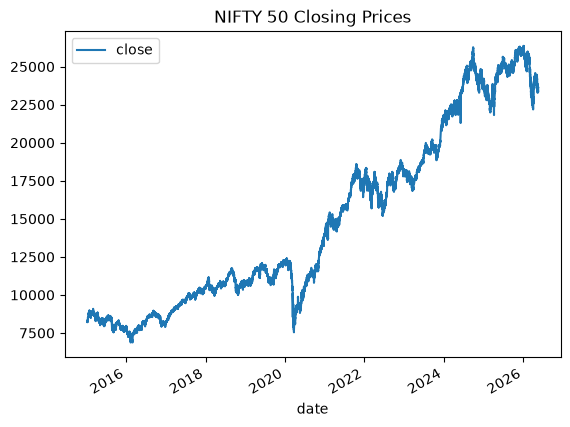

In [6]:
# Plotting the data
nifty_50_df.plot(x="date", y="close", title="NIFTY 50 Closing Prices")

<Axes: title={'center': 'NIFTY 50 Closing Prices'}, xlabel='date'>

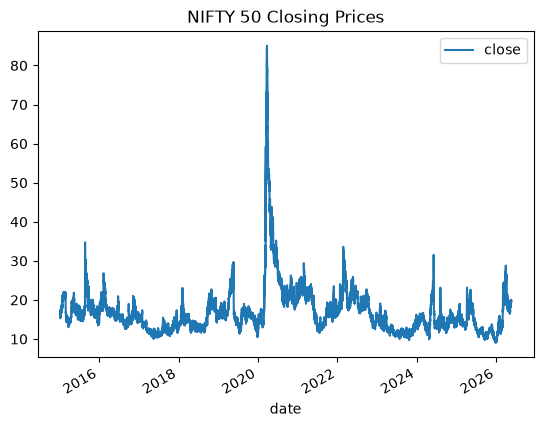

In [7]:
india_vix_df.plot(x="date", y="close", title="NIFTY 50 Closing Prices")

[Text(0, 0, '2026-04-01'),
 Text(335, 0, '2026-04-08'),
 Text(671, 0, '2026-04-15'),
 Text(1007, 0, '2026-04-22'),
 Text(1342, 0, '2026-04-28'),
 Text(1678, 0, '2026-05-06'),
 Text(2014, 0, '2026-05-12'),
 Text(2350, 0, '2026-05-18')]

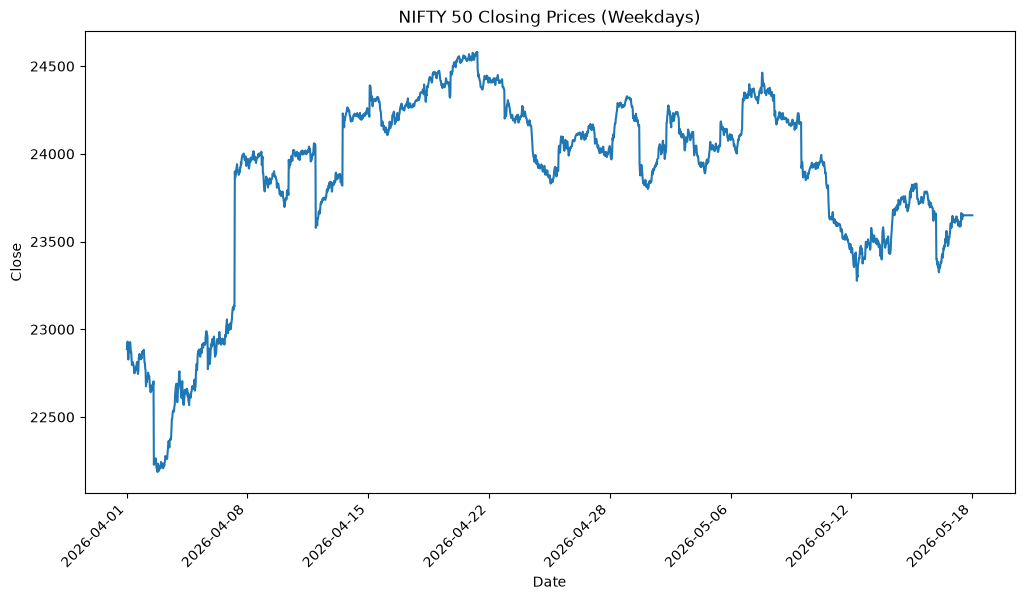

In [8]:
# Plot only last year data
nifty_50_df_last_year = nifty_50_df[nifty_50_df["date"] >= "2026-04-01"]

plt.figure(figsize=(12, 6))

df = nifty_50_df_last_year[
    nifty_50_df_last_year["date"].dt.dayofweek < 5
].reset_index(drop=True)

ax = df["close"].plot(
    title="NIFTY 50 Closing Prices (Weekdays)",
    xlabel="Date",
    ylabel="Close"
)

tick_positions = np.linspace(0, len(df) - 1, 8, dtype=int)
ax.set_xticks(tick_positions)
ax.set_xticklabels(
    df.loc[tick_positions, "date"].dt.strftime("%Y-%m-%d"),
    rotation=45,
    ha="right"
)

### Transform data to continious values using sine function

In [9]:
# sine transformation of time

def get_sine_transformed_time(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])

    # Assumes timestamps are already in Indian market local time.
    seconds_since_midnight = (
        df["date"].dt.hour * 3600
        + df["date"].dt.minute * 60
        + df["date"].dt.second
    )

    session_start = 9 * 3600 + 15 * 60   # 09:15
    session_end = 15 * 3600 + 30 * 60   # 15:30
    df["time"] = seconds_since_midnight - session_start

    phase = 2 * np.pi * df["time"] / (session_end - session_start)
    df["sine_time"] = np.sin(phase)
    df["cosine_time"] = np.cos(phase)

    df["day_of_week"] = df["date"].dt.dayofweek
    weekday_phase = 2 * np.pi * df["day_of_week"] / 7
    df["sine_day_of_week"] = np.sin(weekday_phase)
    df["cosine_day_of_week"] = np.cos(weekday_phase)

    return df

In [10]:
nifty_50_df = get_sine_transformed_time(nifty_50_df)
nifty_bank_df = get_sine_transformed_time(nifty_bank_df)
india_vix_df = get_sine_transformed_time(india_vix_df)

In [11]:
nifty_50_df.head(10)

,date,open,high,low,close,volume,time,sine_time,cosine_time,day_of_week,sine_day_of_week,cosine_day_of_week
0,2015-01-09 09:15:00,8285.45,8301.30,8285.45,8301.20,0,0,0.000000,1.000000,4,-0.433884,-0.900969
1,2015-01-09 09:20:00,8300.50,8303.00,8293.25,8301.00,0,300,0.083678,0.996493,4,-0.433884,-0.900969
2,2015-01-09 09:25:00,8301.65,8302.55,8286.80,8294.15,0,600,0.166769,0.985996,4,-0.433884,-0.900969
3,2015-01-09 09:30:00,8294.10,8295.75,8280.65,8288.50,0,900,0.248690,0.968583,4,-0.433884,-0.900969
4,2015-01-09 09:35:00,8289.10,8290.45,8278.00,8283.45,0,1200,0.328867,0.944376,4,-0.433884,-0.900969
5,2015-01-09 09:40:00,8283.40,8288.30,8277.40,8285.55,0,1500,0.406737,0.913545,4,-0.433884,-0.900969
6,2015-01-09 09:45:00,8285.40,8287.65,8278.05,8283.75,0,1800,0.481754,0.876307,4,-0.433884,-0.900969
7,2015-01-09 09:50:00,8283.80,8284.25,8273.95,8276.25,0,2100,0.553392,0.832921,4,-0.433884,-0.900969
8,2015-01-09 09:55:00,8275.95,8283.60,8275.05,8282.00,0,2400,0.621148,0.783693,4,-0.433884,-0.900969
9,2015-01-09 10:00:00,8281.80,8287.35,8281.70,8285.50,0,2700,0.684547,0.728969,4,-0.433884,-0.900969


### ADDING TECHNICAL FEATURES

In [12]:
# Features for forecasting FUTURE bars after the current five-minute bar closes.
# Windows count observed bars and continue across trading sessions (75 bars ~ 1 day).
# Warm-up NaNs are intentional: never backfill them from future observations.
def add_technical_indicators(df):
    required = {"date", "open", "high", "low", "close"}
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date", kind="stable").reset_index(drop=True)
    if df["date"].isna().any() or df["date"].duplicated().any():
        raise ValueError("Each bar must have a valid, unique timestamp")
    o, h, l, c = (pd.to_numeric(df[col], errors="raise")
                  for col in ["open", "high", "low", "close"])

    def divide(numerator, denominator):
        return numerator / denominator.replace(0, np.nan)

    def wilder(series, window=14):
        # Wilder smoothing, seeded with the first window's simple average.
        seed = series.rolling(window, min_periods=window).mean()
        first = seed.first_valid_index()
        if first is None:
            return pd.Series(np.nan, index=series.index, dtype=float)
        values = series.copy()
        values.loc[:first] = np.nan
        values.loc[first] = seed.loc[first]
        return values.ewm(alpha=1 / window, adjust=False,
                          min_periods=1, ignore_na=False).mean()

    # Returns and lags offer scale-independent price/momentum information.
    df["log_return_1"] = np.log(c.where(c > 0)).diff()
    for window in (1, 3, 6, 12, 24, 75):
        df[f"return_{window}"] = divide(c, c.shift(window)) - 1
    for lag in (1, 2, 3, 6, 12):
        df[f"return_1_lag_{lag}"] = df["return_1"].shift(lag)

    # Trend levels and relative distances from those levels.
    for window in (5, 12, 20, 26, 50, 75):
        sma = c.rolling(window, min_periods=window).mean()
        ema = c.ewm(span=window, adjust=False, min_periods=window).mean()
        df[f"sma_{window}"] = sma
        df[f"ema_{window}"] = ema
        df[f"close_to_sma_{window}"] = divide(c, sma) - 1
        df[f"close_to_ema_{window}"] = divide(c, ema) - 1
    df["macd"] = df["ema_12"] - df["ema_26"]
    df["macd_signal"] = df["macd"].ewm(span=9, adjust=False, min_periods=9).mean()
    df["macd_hist"] = df["macd"] - df["macd_signal"]
    df["macd_pct"] = 100 * divide(df["macd"], c)

    # RSI: flat prices -> 50, gains without losses -> 100.
    change = c.diff()
    gain = wilder(change.clip(lower=0))
    loss = wilder(-change.clip(upper=0))
    df["rsi_14"] = 100 * divide(gain, gain + loss)
    df.loc[(gain == 0) & (loss == 0), "rsi_14"] = 50.0

    low_14 = l.rolling(14, min_periods=14).min()
    high_14 = h.rolling(14, min_periods=14).max()
    df["stoch_k_14"] = 100 * divide(c - low_14, high_14 - low_14)
    df["stoch_d_3"] = df["stoch_k_14"].rolling(3, min_periods=3).mean()

    # Volatility and bands; return volatility is per bar, not annualized.
    previous_close = c.shift(1)
    true_range = pd.concat([h - l, (h - previous_close).abs(),
                            (l - previous_close).abs()], axis=1).max(axis=1)
    df["atr_14"] = wilder(true_range)
    df["atr_pct_14"] = 100 * divide(df["atr_14"], c)
    for window in (12, 20, 75):
        df[f"return_volatility_{window}"] = df["log_return_1"].rolling(
            window, min_periods=window).std(ddof=0)
    middle = df["sma_20"]
    std = c.rolling(20, min_periods=20).std(ddof=0)
    df["bb_upper_20"] = middle + 2 * std
    df["bb_lower_20"] = middle - 2 * std
    df["bb_width_20"] = divide(4 * std, middle)
    df["bb_position_20"] = divide(c - df["bb_lower_20"], 4 * std)
    df["price_zscore_20"] = divide(c - middle, std)

    # Candle shape, gaps, and breakouts against PREVIOUS bars' range.
    df["candle_body_pct"] = divide(c - o, o)
    df["candle_range_pct"] = divide(h - l, c)
    df["upper_wick_pct"] = divide(h - pd.concat([o, c], axis=1).max(axis=1), c)
    df["lower_wick_pct"] = divide(pd.concat([o, c], axis=1).min(axis=1) - l, c)
    df["close_in_range"] = divide(c - l, h - l)
    df["gap_from_previous_close"] = divide(o, previous_close) - 1
    prior_high = h.shift(1).rolling(20, min_periods=20).max()
    prior_low = l.shift(1).rolling(20, min_periods=20).min()
    df["distance_to_prior_high_20"] = divide(c, prior_high) - 1
    df["distance_to_prior_low_20"] = divide(c, prior_low) - 1

    # Index files may have zero/unavailable volume, so omit volume indicators.
    return df


In [13]:
nifty_50_df = add_technical_indicators(nifty_50_df)
nifty_bank_df = add_technical_indicators(nifty_bank_df)

nifty_50_df.tail()

,date,open,high,low,close,volume,time,sine_time,cosine_time,day_of_week,...,bb_position_20,price_zscore_20,candle_body_pct,candle_range_pct,upper_wick_pct,lower_wick_pct,close_in_range,gap_from_previous_close,distance_to_prior_high_20,distance_to_prior_low_20
209883,2026-05-18 17:15:00,23649.95,23649.95,23649.95,23649.95,0,28800,0.982287,-0.187381,0,...,0.5,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0
209884,2026-05-18 17:20:00,23649.95,23649.95,23649.95,23649.95,0,29100,0.963163,-0.268920,0,...,0.5,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0
209885,2026-05-18 17:25:00,23649.95,23649.95,23649.95,23649.95,0,29400,0.937282,-0.348572,0,...,0.5,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0
209886,2026-05-18 17:30:00,23649.95,23649.95,23649.95,23649.95,0,29700,0.904827,-0.425779,0,...,0.5,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0
209887,2026-05-18 17:35:00,23649.95,23649.95,23649.95,23649.95,0,30000,0.866025,-0.500000,0,...,0.5,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0


In [14]:
pprint(nifty_50_df.columns)

Index(['date', 'open', 'high', 'low', 'close', 'volume', 'time', 'sine_time',
       'cosine_time', 'day_of_week', 'sine_day_of_week', 'cosine_day_of_week',
       'log_return_1', 'return_1', 'return_3', 'return_6', 'return_12',
       'return_24', 'return_75', 'return_1_lag_1', 'return_1_lag_2',
       'return_1_lag_3', 'return_1_lag_6', 'return_1_lag_12', 'sma_5', 'ema_5',
       'close_to_sma_5', 'close_to_ema_5', 'sma_12', 'ema_12',
       'close_to_sma_12', 'close_to_ema_12', 'sma_20', 'ema_20',
       'close_to_sma_20', 'close_to_ema_20', 'sma_26', 'ema_26',
       'close_to_sma_26', 'close_to_ema_26', 'sma_50', 'ema_50',
       'close_to_sma_50', 'close_to_ema_50', 'sma_75', 'ema_75',
       'close_to_sma_75', 'close_to_ema_75', 'macd', 'macd_signal',
       'macd_hist', 'macd_pct', 'rsi_14', 'stoch_k_14', 'stoch_d_3', 'atr_14',
       'atr_pct_14', 'return_volatility_12', 'return_volatility_20',
       'return_volatility_75', 'bb_upper_20', 'bb_lower_20', 'bb_width_20',
       

### DATA LOADERS

Each sample uses `SEQ_LEN` completed bars to predict the return of the **next observed bar** (including overnight/weekend gaps). Inputs end at bar t; the target is close[t+1] / close[t] - 1, or its log. Predictions assume bar t has closed.

Windows advance by `WINDOW_STRIDE` bars (default 1), so adjacent samples overlap instead of using fixed non-overlapping chunks. `shuffle=True` changes training window order each epoch while preserving time order inside each sequence; it does not guarantee better generalization. Validation/test are ordered. Splits use **target timestamps**, and evaluation windows may use earlier historical context. Feature scaling uses training rows only. Invalid windows are excluded without joining bars across missing rows.

Inputs include NIFTY 50 plus timestamp-matched INDIA VIX (`vix_`) and NIFTY BANK (`bank_`) prices and technical indicators. Calendar encodings are included only once. Exact left joins preserve the NIFTY 50 timeline; missing auxiliary features invalidate the affected windows rather than being filled with future values. All three bars must be available when forecasting. The target remains NIFTY 50 next-bar return.


In [15]:
SEQ_LEN = 75                 # roughly one trading session
BATCH_SIZE = 64
WINDOW_STRIDE = 1            # one-bar shifts; larger values reduce overlap
TARGET_KIND = "log_return"  # "return" or "log_return"
TRAIN_FRACTION = 0.70
VAL_FRACTION = 0.15
SEED = 42

forecast_df = nifty_50_df.sort_values("date", kind="stable").reset_index(drop=True).copy()
if forecast_df["date"].isna().any() or forecast_df["date"].duplicated().any():
    raise ValueError("Expected unique, valid bar timestamps")

# Keep NIFTY 50's bar timeline and target definition unchanged. Only join
# auxiliary bars with the EXACT same timestamp, available after that bar closes.
# Missing auxiliary bars stay NaN: affected windows are excluded below.
excluded_features = {"volume", "time", "day_of_week"}
feature_columns = [c for c in forecast_df.select_dtypes(include=[np.number]).columns
                   if c not in excluded_features and not c.startswith("target")]
calendar_features = {"sine_time", "cosine_time", "sine_day_of_week", "cosine_day_of_week"}
for prefix, auxiliary_df in (("vix", india_vix_df), ("bank", nifty_bank_df)):
    auxiliary_df = auxiliary_df.copy()
    auxiliary_df["date"] = pd.to_datetime(auxiliary_df["date"])
    if auxiliary_df["date"].isna().any() or auxiliary_df["date"].duplicated().any():
        raise ValueError(f"{prefix}: expected unique, valid bar timestamps")
    auxiliary_columns = [
        c for c in auxiliary_df.select_dtypes(include=[np.number]).columns
        if c not in excluded_features | calendar_features and not c.startswith("target")
    ]
    if not auxiliary_columns:
        raise ValueError(f"{prefix}: no numeric features available")
    renamed_columns = {c: f"{prefix}_{c}" for c in auxiliary_columns}
    forecast_df = forecast_df.merge(
        auxiliary_df[["date"] + auxiliary_columns].rename(columns=renamed_columns),
        on="date", how="left", sort=False, validate="one_to_one",
    )
    feature_columns.extend(renamed_columns.values())
    print(f"{prefix}: {len(auxiliary_columns)} features; "
          f"{forecast_df[f'{prefix}_close'].isna().sum():,} bars without a matching close")

raw_features = forecast_df[feature_columns].to_numpy(dtype=np.float64)
closes = forecast_df["close"].to_numpy(dtype=np.float64)
if not np.all(np.isfinite(closes) & (closes > 0)):
    raise ValueError("Close prices must be finite and positive")

# targets[j] is the return realized AT bar j; inputs end at j-1.
targets = np.full(len(closes), np.nan, dtype=np.float64)
ratios = closes[1:] / closes[:-1]
targets[1:] = np.log(ratios) if TARGET_KIND == "log_return" else ratios - 1
train_end = int(len(forecast_df) * TRAIN_FRACTION)
val_end = int(len(forecast_df) * (TRAIN_FRACTION + VAL_FRACTION))

# Fit only on fully finite training rows; never backfill indicators.
valid_rows = np.isfinite(raw_features).all(axis=1)
fit_rows = raw_features[:train_end][valid_rows[:train_end]]
if not len(feature_columns) or not len(fit_rows):
    raise ValueError("No valid training features; check indicator warm-up/data size")
feature_mean = fit_rows.mean(axis=0)
feature_std = fit_rows.std(axis=0)
feature_std[feature_std < 1e-12] = 1.0
scaled_features = ((raw_features - feature_mean) / feature_std).astype(np.float32)
valid_rows &= np.isfinite(scaled_features).all(axis=1)

# Prefix counts reject any sequence containing a missing/invalid feature row.
invalid_prefix = np.r_[0, np.cumsum(~valid_rows)]
candidate_indices = np.arange(SEQ_LEN, len(forecast_df))
valid_windows = (invalid_prefix[candidate_indices]
                 - invalid_prefix[candidate_indices - SEQ_LEN]) == 0
eligible_indices = candidate_indices[valid_windows & np.isfinite(targets[candidate_indices])]
train_indices = eligible_indices[eligible_indices < train_end][::WINDOW_STRIDE]
val_indices = eligible_indices[(eligible_indices >= train_end) & (eligible_indices < val_end)]
test_indices = eligible_indices[eligible_indices >= val_end]
if any(len(indices) == 0 for indices in (train_indices, val_indices, test_indices)):
    raise ValueError("An empty split: reduce SEQ_LEN or supply more valid data")

vix: 4 features; 79 bars without a matching close
bank: 65 features; 9 bars without a matching close


In [16]:
class NextBarWindowDataset(Dataset):
    """Lazy overlapping windows; no large materialized [windows, sequence, features] array."""

    def __init__(self, features, targets, target_indices, seq_len):
        self.features = features
        self.targets = targets
        self.target_indices = np.asarray(target_indices, dtype=np.int64)
        self.seq_len = seq_len

    def __len__(self):
        return len(self.target_indices)

    def __getitem__(self, index):
        j = int(self.target_indices[index])
        return self.features[j - self.seq_len:j], self.targets[j:j + 1]


# All splits share the underlying tensors; only their target indices differ.
feature_tensor = torch.from_numpy(scaled_features)
target_tensor = torch.from_numpy(targets.astype(np.float32))
train_dataset, val_dataset, test_dataset = [
    NextBarWindowDataset(feature_tensor, target_tensor, indices, SEQ_LEN)
    for indices in (train_indices, val_indices, test_indices)
]
# Seed once: do NOT recreate/reseed the generator inside each epoch.
train_generator = torch.Generator().manual_seed(SEED)
loader_options = dict(batch_size=BATCH_SIZE, num_workers=0, drop_last=False)
train_loader = DataLoader(train_dataset, shuffle=True, generator=train_generator, **loader_options)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_options)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

for name, dataset in [("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)]:
    dates = forecast_df.loc[dataset.target_indices, "date"]
    print(f"{name}: {len(dataset):,} windows | targets {dates.iloc[0]} to {dates.iloc[-1]}")
print(f"Features: {len(feature_columns)} | target: {TARGET_KIND}")

train: 146,025 windows | targets 2015-01-13 09:15:00 to 2022-12-20 14:20:00
validation: 31,483 windows | targets 2022-12-20 14:25:00 to 2024-09-03 14:40:00
test: 31,460 windows | targets 2024-09-03 14:45:00 to 2026-05-18 15:35:00
Features: 138 | target: log_return


In [17]:
# Inspect one batch: X = [batch, sequence, features], y = [batch, 1].
X_batch, y_batch = next(iter(train_loader))
assert X_batch.shape[1:] == (SEQ_LEN, len(feature_columns))
assert y_batch.shape == (len(X_batch), 1)
assert torch.isfinite(X_batch).all() and torch.isfinite(y_batch).all()
print("X:", tuple(X_batch.shape), "y:", tuple(y_batch.shape))

# Check exact target alignment on the first training window.
j = int(train_dataset.target_indices[0])
expected = np.log(closes[j] / closes[j - 1]) if TARGET_KIND == "log_return" else closes[j] / closes[j - 1] - 1
np.testing.assert_allclose(train_dataset[0][1].item(), expected, rtol=1e-6, atol=1e-8)

# Iterate the SAME loader each epoch to get a new shuffle of shifted windows:
# for epoch in range(num_epochs):
#     for X, y in train_loader:
#         prediction = model(X)  # output shape [batch, 1]
#         loss = loss_fn(prediction, y)
#         ...

# Convert a predicted return back to a next-close forecast using the last input close.
def return_to_next_close(last_close, predicted_return, target_kind=TARGET_KIND):
    last_close = np.asarray(last_close)
    predicted_return = np.asarray(predicted_return)
    if target_kind == "log_return":
        return last_close * np.exp(predicted_return)
    if target_kind == "return":
        return last_close * (1 + predicted_return)
    raise ValueError("Unknown target kind")

# For ordered test predictions shaped [N, 1], first flatten to [N]:
# predicted_closes = return_to_next_close(
#     closes[test_indices - 1], test_predictions.reshape(-1))

X: (64, 75, 138) y: (64, 1)


### MODEL, Loss function and Optimizer

The BiLSTM and dense head output raw next-bar returns. Internally, the head works in units of the training return standard deviation and then converts back to raw returns. Only training targets determine this scale; no mean is subtracted, preserving the zero direction boundary.

`ReturnDirectionLoss` combines normalized MSE with `softplus(-sign(actual) * scaled_prediction)`. This directional term has a nonzero corrective gradient for wrong signs, unlike `sign(prediction)`. Flat targets contribute only to regression. Validation logs report directional accuracy, predicted up/down proportions, and the majority-class baseline. Early stopping still selects the lowest combined validation loss. Mixed predictions and higher accuracy are not guaranteed: the features must contain learnable signal. Retrain from initialization after this change; old model weights and outputs are not results for this objective.


In [18]:
class ReturnDirectionLoss(nn.Module):
    """Scale-normalized regression plus differentiable sign classification.

    Inputs/outputs remain raw returns. Scaling without mean subtraction
    preserves zero as the boundary between up and down.
    """
    def __init__(self, return_scale, direction_weight=5.0):
        super().__init__()
        if return_scale <= 0 or direction_weight < 0:
            raise ValueError("Scale must be positive and direction weight nonnegative")
        self.return_scale = float(return_scale)
        self.direction_weight = direction_weight

    def forward(self, y_pred, y_true):
        pred = y_pred / self.return_scale
        actual = y_true / self.return_scale
        regression = torch.nn.functional.mse_loss(pred, actual)
        # Flat targets contribute regression only. Unlike sign(pred),
        # softplus has a useful gradient for wrong-direction predictions.
        moving = (actual != 0).to(pred.dtype)
        direction = (torch.nn.functional.softplus(-actual.sign() * pred)
                     * moving).sum() / moving.sum().clamp_min(1)
        return regression + self.direction_weight * direction


In [19]:
class BiLSTMRegressor(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=1,
                 head_size=32, dropout=0.2, return_scale=1.0):
        super().__init__()
        self.register_buffer("return_scale", torch.tensor(float(return_scale)))
        self.lstm = nn.LSTM(
            input_size=input_size, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True, bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.head = nn.Sequential(
            nn.Linear(2 * hidden_size, head_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(head_size, 1),
        )

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        # Last layer: final forward and final backward representations.
        summary = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.head(summary) * self.return_scale

HIDDEN_SIZE = 64
NUM_LAYERS = 1
HEAD_SIZE = 32
DROPOUT = 0.2
LEARNING_RATE = 1e-3
NUM_EPOCHS = 20
PATIENCE = 5
MAX_GRAD_NORM = 1.0

# Fit the output/loss scale ONLY on eligible training targets.
# No centering: positive/negative scaled values keep their financial meaning.
RETURN_SCALE = float(np.std(targets[train_indices], ddof=0))
if not np.isfinite(RETURN_SCALE) or RETURN_SCALE <= 1e-12:
    raise ValueError("Training returns need nonzero finite variance")
DIRECTION_WEIGHT = 5.0  # 10x previous directional weight; tune on validation only.
print(f"Training return scale: {RETURN_SCALE:.6g}")

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
model = BiLSTMRegressor(
    input_size=len(feature_columns), hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS, head_size=HEAD_SIZE, dropout=DROPOUT,
    return_scale=RETURN_SCALE,
).to(DEVICE)
loss_fn = ReturnDirectionLoss(RETURN_SCALE, direction_weight=DIRECTION_WEIGHT)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(f"Device: {DEVICE} | parameters: {sum(p.numel() for p in model.parameters()):,}")
print(model)

Training return scale: 0.00118802
Device: cuda | parameters: 108,609
BiLSTMRegressor(
  (lstm): LSTM(138, 64, batch_first=True, bidirectional=True)
  (head): Sequential(
    (0): Linear(in_features=128, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [20]:
def train_model(model, train_loader, val_loader, loss_fn, optimizer,
                num_epochs=20, patience=5, max_grad_norm=1.0):
    """Train with a scalar mean loss; restore best model AND optimizer state.

    Place the model on its device before constructing the optimizer.
    Returns per-epoch metrics, best epoch/loss, and early-stopping status.
    """
    if num_epochs < 1 or patience < 1 or max_grad_norm <= 0:
        raise ValueError("Epochs, patience and gradient limit must be positive")
    if len(train_loader) == 0 or len(val_loader) == 0:
        raise ValueError("Training and validation loaders must be nonempty")
    device = next(model.parameters()).device
    history = {"train_loss": [], "val_loss": [], "val_direction_accuracy": [],
               "val_predicted_up_pct": [], "val_predicted_down_pct": [],
               "val_majority_baseline_accuracy": []}
    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0

    def run_epoch(loader, training):
        model.train(training)
        total_loss, total_samples = 0.0, 0
        correct = pred_up = pred_down = actual_up = actual_down = actual_flat = 0
        with torch.set_grad_enabled(training):
            for X, y in loader:
                X, y = X.to(device), y.to(device)
                if training:
                    optimizer.zero_grad(set_to_none=True)
                prediction = model(X)
                if prediction.shape != y.shape:
                    raise ValueError(f"Output {prediction.shape} != target {y.shape}")
                loss = loss_fn(prediction, y)
                if loss.ndim != 0 or not torch.isfinite(loss).item():
                    raise ValueError("Expected a finite scalar mean loss")
                if training:
                    loss.backward()
                    nn.utils.clip_grad_norm_(
                        model.parameters(), max_grad_norm, error_if_nonfinite=True)
                    optimizer.step()
                if not training:
                    correct += (prediction.sign() == y.sign()).sum().item()
                    pred_up += (prediction > 0).sum().item()
                    pred_down += (prediction < 0).sum().item()
                    actual_up += (y > 0).sum().item()
                    actual_down += (y < 0).sum().item()
                    actual_flat += (y == 0).sum().item()
                total_loss += loss.item() * len(X)
                total_samples += len(X)
        diagnostics = {
            "val_direction_accuracy": 100 * correct / total_samples,
            "val_predicted_up_pct": 100 * pred_up / total_samples,
            "val_predicted_down_pct": 100 * pred_down / total_samples,
            "val_majority_baseline_accuracy": 100 * max(actual_up, actual_down, actual_flat) / total_samples,
        }
        return total_loss / total_samples, diagnostics

    for epoch in range(1, num_epochs + 1):
        train_loss, _ = run_epoch(train_loader, training=True)
        val_loss, diagnostics = run_epoch(val_loader, training=False)
        for key, value in diagnostics.items():
            history[key].append(value)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        print(f"Epoch {epoch:02d}/{num_epochs} | "
              f"train loss: {train_loss:.6f} | val loss: {val_loss:.6f} | "
              f"direction: {diagnostics['val_direction_accuracy']:.2f}% | "
              f"up/down: {diagnostics['val_predicted_up_pct']:.1f}%/"
              f"{diagnostics['val_predicted_down_pct']:.1f}% | "
              f"majority baseline: {diagnostics['val_majority_baseline_accuracy']:.2f}%")
        if val_loss < best_val_loss:
            best_val_loss, best_epoch = val_loss, epoch
            best_state = (deepcopy(model.state_dict()), deepcopy(optimizer.state_dict()))
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print(f"Early stopping at epoch {epoch}")
                break

    model.load_state_dict(best_state[0])
    optimizer.load_state_dict(best_state[1])
    model.eval()
    print(f"Restored epoch {best_epoch} | validation loss: {best_val_loss:.8e}")
    return {"history": history, "best_epoch": best_epoch,
            "best_val_loss": best_val_loss,
            "stopped_early": len(history["train_loss"]) < num_epochs}

### Train the model

Run the following cell to fit the model. Rerun the model/optimizer initialization cell first for a fresh training run. CPU training over all windows may take time. The restored model is in evaluation mode; call `model.train()` if continuing training outside the helper. Training loss includes dropout and changing weights, while validation loss uses fixed weights with dropout disabled.

Epoch 01/20 | train loss: 4.467147 | val loss: 3.938414 | direction: 50.61% | up/down: 41.6%/58.4% | majority baseline: 51.08%
Epoch 02/20 | train loss: 4.462420 | val loss: 3.942896 | direction: 48.79% | up/down: 0.8%/99.2% | majority baseline: 51.08%
Epoch 03/20 | train loss: 4.454239 | val loss: 3.938080 | direction: 50.92% | up/down: 49.8%/50.2% | majority baseline: 51.08%
Epoch 04/20 | train loss: 4.450029 | val loss: 3.939434 | direction: 50.83% | up/down: 76.8%/23.2% | majority baseline: 51.08%
Epoch 05/20 | train loss: 4.441039 | val loss: 3.940146 | direction: 50.63% | up/down: 60.1%/39.9% | majority baseline: 51.08%
Epoch 06/20 | train loss: 4.431146 | val loss: 3.946673 | direction: 50.65% | up/down: 35.8%/64.2% | majority baseline: 51.08%
Epoch 07/20 | train loss: 4.423921 | val loss: 3.945553 | direction: 50.57% | up/down: 44.7%/55.3% | majority baseline: 51.08%
Epoch 08/20 | train loss: 4.412552 | val loss: 3.941992 | direction: 50.96% | up/down: 89.6%/10.4% | majority ba

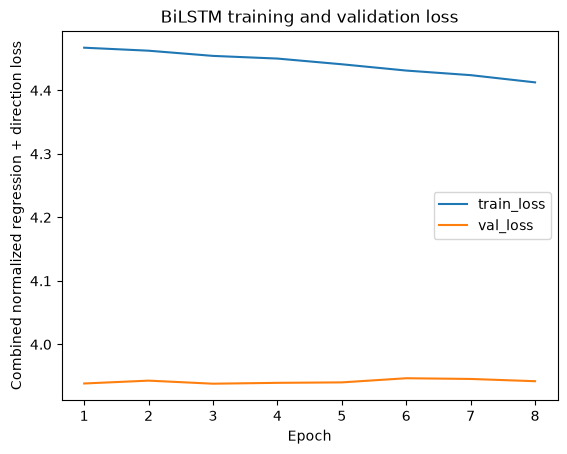

In [21]:
training_result = train_model(
    model, train_loader, val_loader, loss_fn, optimizer,
    num_epochs=NUM_EPOCHS, patience=PATIENCE, max_grad_norm=MAX_GRAD_NORM,
)

history_df = pd.DataFrame(training_result["history"])
history_df.index = np.arange(1, len(history_df) + 1)
history_df[["train_loss", "val_loss"]].plot(xlabel="Epoch", ylabel="Combined normalized regression + direction loss",
                title="BiLSTM training and validation loss")
plt.show()

### TEST THE MODEL

Run after training to evaluate the restored model on the ordered, held-out test set. Metrics below are computed directly from log returns, independently of the training loss. Direction uses three classes: down (< 0), flat (= 0), and up (> 0); a prediction is correct only if its class matches the actual class. No threshold is tuned on test data. Every prediction is associated with its target timestamp and previous input close.

In [22]:
def evaluate_test_model(model, test_loader, forecast_df, closes,
                        target_kind="log_return"):
    if target_kind != "log_return":
        raise ValueError("This section evaluates log returns. Train with TARGET_KIND='log_return' first.")
    if not isinstance(test_loader.sampler, torch.utils.data.SequentialSampler):
        raise ValueError("Test loader must be ordered (shuffle=False)")
    if test_loader.drop_last:
        raise ValueError("Use drop_last=False to evaluate every test sample")
    device = next(model.parameters()).device
    predictions, actuals = [], []
    was_training = model.training
    model.eval()
    try:
        with torch.inference_mode():
            for X, y in test_loader:
                predicted = model(X.to(device))
                if predicted.shape != y.shape:
                    raise ValueError("Prediction and target shapes must match")
                predictions.append(predicted.cpu().numpy().reshape(-1))
                actuals.append(y.cpu().numpy().reshape(-1))
    finally:
        model.train(was_training)
    if not predictions:
        raise ValueError("Test loader is empty")
    predicted = np.concatenate(predictions).astype(np.float64)
    actual = np.concatenate(actuals).astype(np.float64)
    indices = np.asarray(test_loader.dataset.target_indices)
    if len(indices) != len(predicted):
        raise ValueError("Prediction count does not match test target indices")
    if not (np.isfinite(predicted).all() and np.isfinite(actual).all()):
        raise ValueError("Test predictions and targets must be finite")
    expected = np.log(closes[indices] / closes[indices - 1])
    np.testing.assert_allclose(actual, expected, rtol=1e-5, atol=1e-8)
    labels = np.array(["down", "flat", "up"])
    results = pd.DataFrame({
        "date": forecast_df.loc[indices, "date"].to_numpy(),
        "last_input_close": closes[indices - 1],
        "actual_close": closes[indices],
        "actual_log_return": actual,
        "predicted_log_return": predicted,
        "actual_direction": labels[np.sign(actual).astype(int) + 1],
        "predicted_direction": labels[np.sign(predicted).astype(int) + 1],
    })
    results["error"] = predicted - actual
    results["absolute_error"] = np.abs(results["error"])
    results["direction_correct"] = results["actual_direction"] == results["predicted_direction"]
    mse = np.mean((predicted - actual) ** 2)
    metrics = pd.Series({
        "samples": len(results),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": np.mean(np.abs(predicted - actual)),
        "zero_return_baseline_RMSE": np.sqrt(np.mean(actual ** 2)),
        "direction_accuracy_pct": 100 * results["direction_correct"].mean(),
        "correct_direction_count": int(results["direction_correct"].sum()),
        "incorrect_direction_count": int((~results["direction_correct"]).sum()),
    }, name="test")
    return results, metrics


test_results, test_metrics = evaluate_test_model(
    model, test_loader, forecast_df, closes, target_kind=TARGET_KIND,
)
print(test_metrics.to_string())

samples                      3.146000e+04
MSE                          9.709308e-07
RMSE                         9.853582e-04
MAE                          5.291627e-04
zero_return_baseline_RMSE    9.868377e-04
direction_accuracy_pct       5.051176e+01
correct_direction_count      1.589100e+04
incorrect_direction_count    1.556900e+04


In [23]:
from IPython.display import display

# Each table preserves the target timestamps, allowing individual errors to be inspected.
correct_predictions = test_results.loc[test_results["direction_correct"]].copy()
incorrect_predictions = test_results.loc[~test_results["direction_correct"]].copy()
direction_summary = test_results.groupby("actual_direction")["direction_correct"].agg(
    total="size", correct="sum", accuracy="mean",
).reindex(["down", "flat", "up"])
direction_summary["incorrect"] = direction_summary["total"] - direction_summary["correct"]
direction_summary["accuracy_pct"] = 100 * direction_summary.pop("accuracy")
print("Direction performance by actual movement (absent classes remain NaN):")
display(direction_summary)

confusion_matrix = pd.crosstab(
    test_results["actual_direction"], test_results["predicted_direction"],
).reindex(index=["down", "flat", "up"], columns=["down", "flat", "up"], fill_value=0)
print("Direction confusion matrix: rows = actual, columns = predicted")
display(confusion_matrix)
print("Correct directions — first 10 timestamps:")
display(correct_predictions.head(10))
print("Incorrect directions — first 10 timestamps:")
display(incorrect_predictions.head(10))
# Full records remain available in test_results / correct_predictions / incorrect_predictions.

Direction performance by actual movement (absent classes remain NaN):


,total,correct,incorrect,accuracy_pct
actual_direction,,,,
down,15681,8134,7547,51.871692
flat,51,0,51,0.000000
up,15728,7757,7971,49.319685


Direction confusion matrix: rows = actual, columns = predicted


predicted_direction,down,flat,up
actual_direction,,,
down,8134,0,7547
flat,28,0,23
up,7971,0,7757


Correct directions — first 10 timestamps:


,date,last_input_close,actual_close,actual_log_return,predicted_log_return,actual_direction,predicted_direction,error,absolute_error,direction_correct
0,2024-09-03 14:45:00,25284.65,25291.50,0.000271,1.021520e-06,up,up,-0.000270,0.000270,True
3,2024-09-03 15:00:00,25299.80,25280.65,-0.000757,-2.689459e-06,down,down,0.000755,0.000755,True
4,2024-09-03 15:05:00,25280.65,25280.50,-0.000006,-1.648027e-06,down,down,0.000004,0.000004,True
5,2024-09-03 15:10:00,25280.50,25276.30,-0.000166,-9.483963e-07,down,down,0.000165,0.000165,True
7,2024-09-03 15:20:00,25281.30,25275.80,-0.000218,-2.734845e-06,down,down,0.000215,0.000215,True
8,2024-09-03 15:25:00,25275.80,25268.85,-0.000275,-1.462624e-06,down,down,0.000274,0.000274,True
9,2024-09-04 09:15:00,25268.85,25099.90,-0.006709,-3.016458e-06,down,down,0.006706,0.006706,True
10,2024-09-04 09:20:00,25099.90,25112.05,0.000484,1.522042e-06,up,up,-0.000482,0.000482,True
12,2024-09-04 09:30:00,25104.70,25109.15,0.000177,5.759289e-06,up,up,-0.000171,0.000171,True
15,2024-09-04 09:45:00,25095.30,25113.55,0.000727,5.725504e-06,up,up,-0.000721,0.000721,True


Incorrect directions — first 10 timestamps:


,date,last_input_close,actual_close,actual_log_return,predicted_log_return,actual_direction,predicted_direction,error,absolute_error,direction_correct
1,2024-09-03 14:50:00,25291.50,25295.80,0.000170,-2.069184e-07,up,down,-0.000170,0.000170,False
2,2024-09-03 14:55:00,25295.80,25299.80,0.000158,-3.126612e-06,up,down,-0.000161,0.000161,False
6,2024-09-03 15:15:00,25276.30,25281.30,0.000198,-2.199798e-06,up,down,-0.000200,0.000200,False
11,2024-09-04 09:25:00,25112.05,25104.70,-0.000293,7.889278e-06,down,up,0.000301,0.000301,False
13,2024-09-04 09:35:00,25109.15,25108.75,-0.000016,9.511183e-06,down,up,0.000025,0.000025,False
14,2024-09-04 09:40:00,25108.75,25095.30,-0.000536,6.841971e-06,down,up,0.000543,0.000543,False
18,2024-09-04 10:00:00,25127.45,25127.25,-0.000008,3.920724e-06,down,up,0.000012,0.000012,False
21,2024-09-04 10:15:00,25152.45,25143.90,-0.000340,1.895242e-06,down,up,0.000342,0.000342,False
23,2024-09-04 10:25:00,25135.65,25124.25,-0.000454,5.426455e-06,down,up,0.000459,0.000459,False
24,2024-09-04 10:30:00,25124.25,25101.15,-0.000920,6.095559e-06,down,up,0.000926,0.000926,False


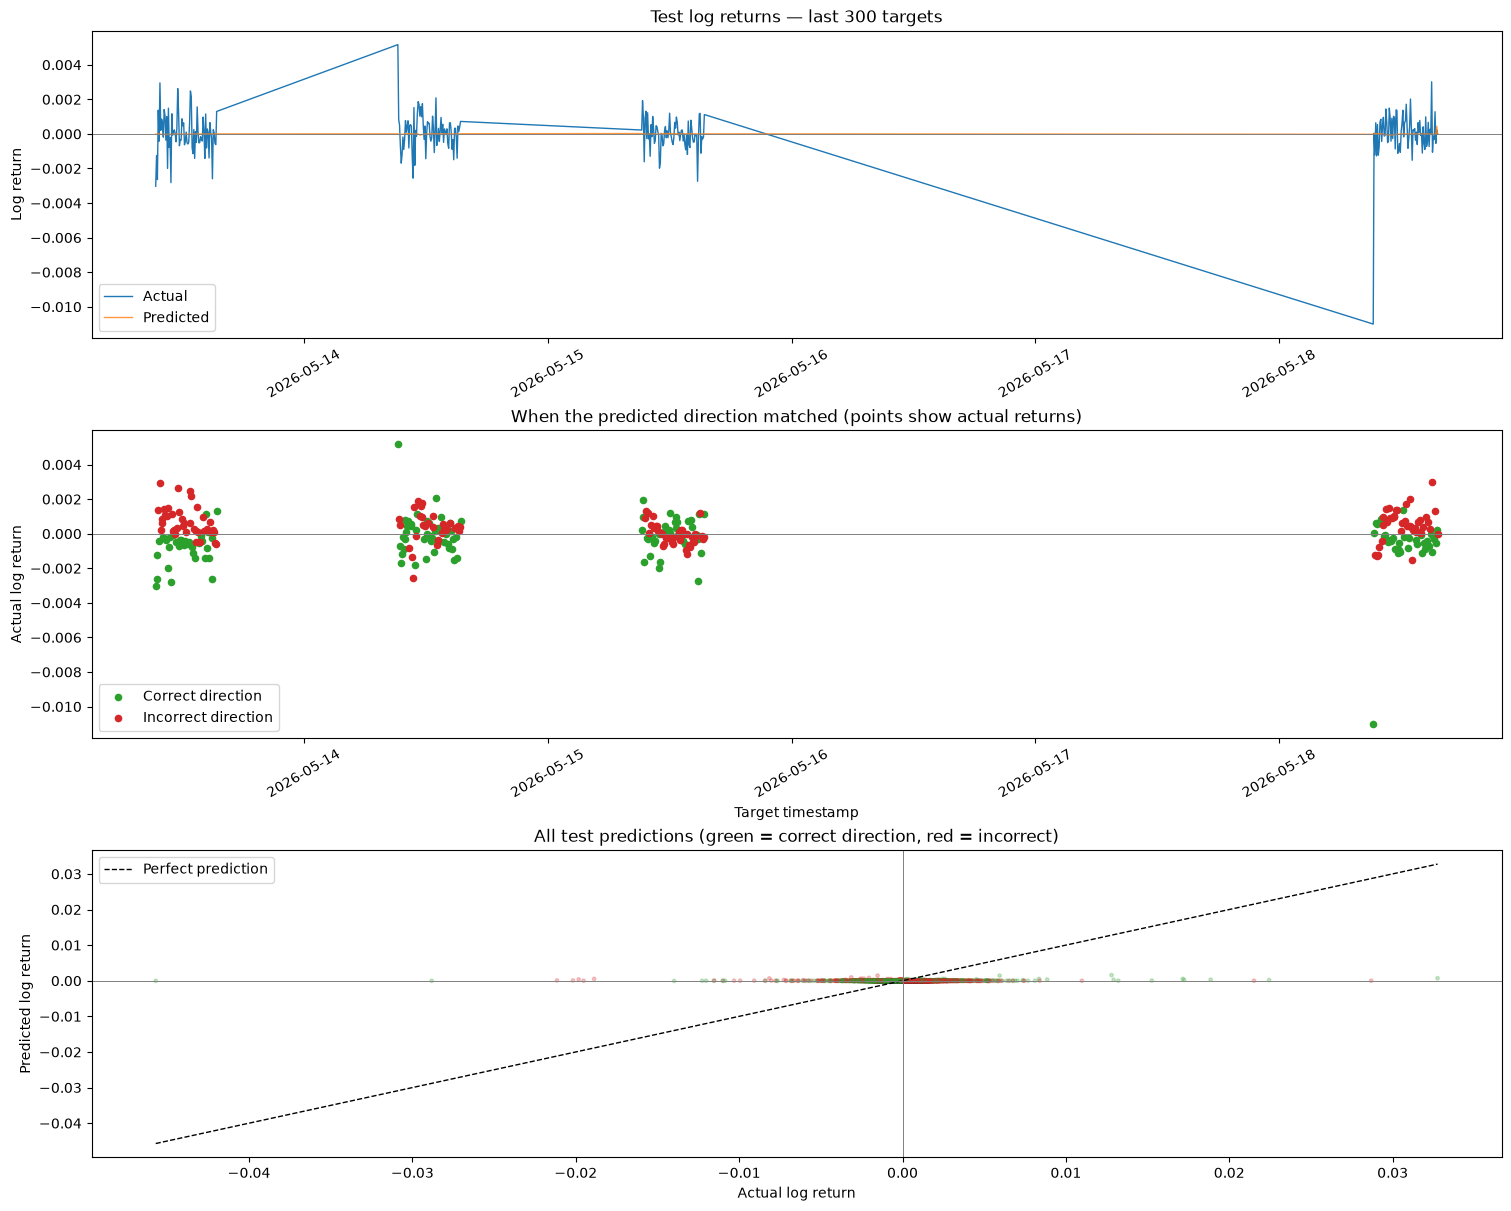

In [24]:
# A readable recent interval; all metrics and the scatter use the entire test set.
PLOT_LAST_N = 300
recent = test_results.tail(PLOT_LAST_N)
fig, axes = plt.subplots(3, 1, figsize=(15, 12), constrained_layout=True)
axes[0].plot(recent["date"], recent["actual_log_return"], label="Actual", linewidth=1)
axes[0].plot(recent["date"], recent["predicted_log_return"], label="Predicted", linewidth=1, alpha=0.8)
axes[0].axhline(0, color="gray", linewidth=0.7)
axes[0].set(title=f"Test log returns — last {len(recent)} targets", ylabel="Log return")
axes[0].legend()

for correct, color, label in [(True, "tab:green", "Correct direction"),
                               (False, "tab:red", "Incorrect direction")]:
    subset = recent.loc[recent["direction_correct"] == correct]
    axes[1].scatter(subset["date"], subset["actual_log_return"],
                    color=color, label=label, s=20)
axes[1].axhline(0, color="gray", linewidth=0.7)
axes[1].set(title="When the predicted direction matched (points show actual returns)",
            ylabel="Actual log return", xlabel="Target timestamp")
axes[1].legend()
for ax in axes[:2]:
    ax.tick_params(axis="x", rotation=30)

colors = np.where(test_results["direction_correct"], "tab:green", "tab:red")
axes[2].scatter(test_results["actual_log_return"], test_results["predicted_log_return"],
                c=colors, s=6, alpha=0.25, rasterized=True)
limits = [test_results[["actual_log_return", "predicted_log_return"]].min().min(),
          test_results[["actual_log_return", "predicted_log_return"]].max().max()]
axes[2].plot(limits, limits, "k--", linewidth=1, label="Perfect prediction")
axes[2].axhline(0, color="gray", linewidth=0.7)
axes[2].axvline(0, color="gray", linewidth=0.7)
axes[2].set(title="All test predictions (green = correct direction, red = incorrect)",
            xlabel="Actual log return", ylabel="Predicted log return")
axes[2].legend()
plt.show()